TASK C (Voronoi Diagrams)

In this task, the goal is to divide Leeds into four marathon service areas (“cells”) so that citizens can join a nearby event, and then investigate whether each cell can support a closed marathon route of approximately 42 km.

Unlike Tasks A and B, this task is not restricted to the 1 km² central study area. A full marathon route requires a much larger operational road network, so Task C uses a broader Leeds road network. The overall workflow follows the same practical structure as the labs:

1. build a suitable road network,
2. choose and justify four seed points,
3. construct Voronoi cells on the network,
4. search for closed marathon routes inside the cells,
5. evaluate whether all cells are feasible,
6. test one alternative configuration if needed.

The implementation is designed to remain close to the lab logic on spatial networks and network Voronoi diagrams, while keeping the route-search part transparent and reproducible.

In [1]:
# Uncomment if needed the first time:
# %pip install osmnx geopandas networkx shapely

from pathlib import Path
import os

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

from shapely.geometry import Point, LineString
from itertools import combinations

ox.settings.use_cache = True
ox.settings.log_console = True

This sets up the working environment and turns on local caching in OSMnx so repeated queries are less expensive. This is helpful because Task C uses a larger city-scale graph and can be more computationally demanding than Tasks A and B. OSMnx’s documentation explicitly supports downloading place-based street networks and geospatial features, as well as local caching. 

Step 1: Download and prepare a broader Leeds road network

Task C is city-wide in spirit, so the road graph is built for Leeds rather than for the smaller Task A box. A drivable network is used because the marathon routes are intended to follow the road system.

After downloading, the graph is:

- projected to a metric CRS,
- converted to an undirected graph for route design,
- restricted to its largest connected component.

In [2]:
place_query = "Leeds, West Yorkshire, England, United Kingdom"

G_drive = ox.graph_from_place(
    place_query,
    network_type="drive",
    simplify=True,
    retain_all=False,
    truncate_by_edge=False
)

G_proj = ox.project_graph(G_drive)
Gu = ox.convert.to_undirected(G_proj)

# Keep only the largest connected component
largest_cc = max(nx.connected_components(Gu), key=len)
Gu = Gu.subgraph(largest_cc).copy()

print("Nodes:", Gu.number_of_nodes())
print("Edges:", Gu.number_of_edges())

Nodes: 31600
Edges: 37904


In [4]:
# GeoDataFrames for plotting and feature work
nodes_gdf, edges_gdf = ox.graph_to_gdfs(Gu, nodes=True, edges=True, fill_edge_geometry=True)

# Keep nodes indexed by node id
# Reset edges for easier processing
edges_gdf = edges_gdf.reset_index().copy()

print(nodes_gdf.head())
print(edges_gdf.head())

                       y              x            highway  ref  street_count  \
osmid                                                                           
154962      5.967507e+06  609019.669000  motorway_junction   44             3   
3504720     5.968045e+06  608908.264418                NaN  NaN             3   
30804402    5.969337e+06  608751.291079                NaN  NaN             3   
155002      5.958057e+06  598942.335306                NaN  NaN             3   
1596671811  5.956972e+06  597875.366334                NaN  NaN             3   

           junction railway                        geometry  
osmid                                                        
154962          NaN     NaN  POINT (609019.669 5967507.057)  
3504720         NaN     NaN  POINT (608908.264 5968045.016)  
30804402        NaN     NaN  POINT (608751.291 5969337.492)  
155002          NaN     NaN  POINT (598942.335 5958057.069)  
1596671811      NaN     NaN  POINT (597875.366 5956972.102) 

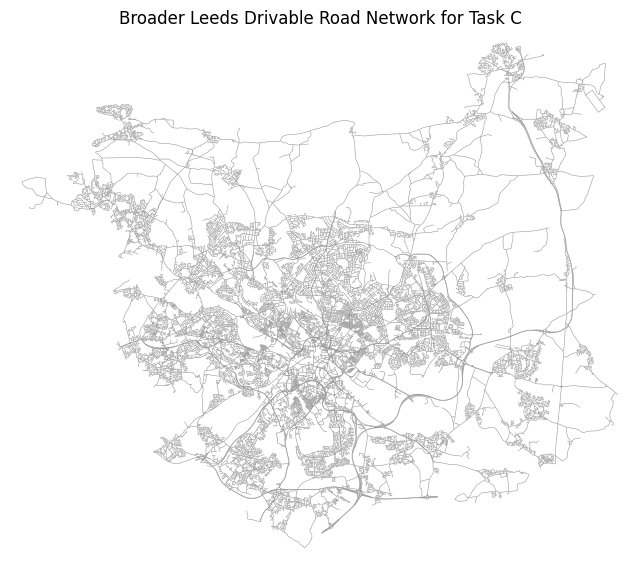

In [5]:
fig, ax = ox.plot_graph(
    Gu,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    show=False,
    close=False
)
ax.set_title("Broader Leeds Drivable Road Network for Task C")
plt.show()

A broader Leeds road network is now available for city-scale marathon planning. This is the correct scale for Task C because the objective is to design four simultaneous marathon areas, each of which should ideally be capable of supporting an approximately 42 km closed route.

Step 2: Build a simplified weighted graph for Voronoi and route search

The original OSMnx graph may contain parallel edges. For shortest-path Voronoi partitioning and route search, a simpler undirected weighted graph is easier to work with. Therefore, a simple graph is created in which:

- nodes retain their coordinates,
- each pair of connected nodes keeps the minimum edge length among parallel edges.

This preserves the weighted road-network structure needed for shortest-path analysis.

In [6]:
def multigraph_to_simple_min(G_multi):
    G_simple = nx.Graph()

    for n, data in G_multi.nodes(data=True):
        G_simple.add_node(n, **data)

    for u, v, data in G_multi.edges(data=True):
        length = data.get("length", 1.0)

        if G_simple.has_edge(u, v):
            if length < G_simple[u][v]["length"]:
                G_simple[u][v]["length"] = length
        else:
            G_simple.add_edge(u, v, length=length)

    return G_simple

G_simple = multigraph_to_simple_min(Gu)

print("Simple graph nodes:", G_simple.number_of_nodes())
print("Simple graph edges:", G_simple.number_of_edges())

Simple graph nodes: 31600
Simple graph edges: 37655


The simple weighted graph is used only for shortest-path-based partitioning and route construction. The richer OSMnx graph and edge geometries are still retained for plotting.